In [2]:
from functions.functions_segmentation_benchmark import obtain_output_inference
import pandas as pd
import os
import matplotlib.pyplot as plt
import re
from collections import defaultdict

Parameters


In [3]:
# microwells to delete because no correspondance between video and nomenclature
# (the nomenclature name is wrong)
bad_mw = ["TR9-C01_tile008_a4",\
          "(HPC_3000)_tile009_d1"]
# path in which we save the figures for the paper   
path_save = r"Figures"
os.makedirs(path_save, exist_ok=True)

Load groundtruth and results 

In [4]:
# path for results and groundtruth
cellpose_results = r"..\groundtruth\Cellpose" 
gt_path = r"../groundtruth"

# extract the groundtruths in a dataframe
name_gt = "MB_Groundtruths_corrected.xlsx"
sheet_names = ["MB_250807", "MB_251003"]
dfs = []
for sheet_name in sheet_names: # read each sheet
    df = pd.read_excel(os.path.join(gt_path, name_gt), sheet_name=sheet_name)
    dfs.append(df)
df_gt = pd.concat(dfs, axis=1) # concatenate by column
df_gt.columns = df_gt.iloc[0] # the first row becomes the header column name
df_gt = df_gt[1:].reset_index(drop=True) # take only the values
# drop the bad nomenclature wells
df_gt = df_gt.drop(bad_mw, axis=1)

In [5]:
from functions.functions_segmentation_benchmark import obtain_performances
df_results =obtain_output_inference(cellpose_results, col_name="Correction")
raw_data = obtain_performances(df_results, df_gt, computation_type="nine") # compute


No GT match found for Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile009_d1_HPC_3000_GT
No GT match found for Pos_output_MB_250807_sherlock_New-01-Scene-09-TR9-C01_tile008_a4_Scene009_GT


In [6]:
# find name of files
path_results = r"../divisiontimes" #"../../Final"
name_scenes = os.listdir(path_results)
name_scenes = [scene for scene in name_scenes if scene.endswith(".csv")]
print(f"Before deletion: {name_scenes}")
# exclude csv files that are not going to be used here
if "output_MB03102025_new_HPC_3000.csv" in name_scenes:
    name_scenes.remove("output_MB03102025_new_HPC_3000.csv")
    print("Removed output_MB03102025_new_HPC_3000.csv from name_scenes")


print(f"After deletion: {name_scenes}")

# Dictionary in which the experiments are the keys
# and the values are the list of scenes corresponding to each experiment (not loaded yet)
exp_dict = defaultdict(list)
for scene in name_scenes:
    # extract key experiment
    m = re.match(r'output_(MB\d+)', scene)
    if m:
        exp_key = m.group(1)
        exp_dict[exp_key].append(scene)

# order file list
for k in exp_dict:
    exp_dict[k] = sorted(exp_dict[k])

# visualize dict
print(f"Final dictionary: {exp_dict}\n")
# count elements in dict
print("Number of scenes per experiment:")
for key, files in exp_dict.items():
    print(f"{key}: {len(files)} scenes")

def add_condition_column(name_scenes,exp, path_results, equivalence_dict):
    # obtain a flat df with a new column "Condition" and "Exp_name" for each scene in name_scenes
    global_df = []
    for scene in name_scenes:
        df = pd.read_csv(os.path.join(path_results, scene))
        name_key = equivalence_dict[scene]
        df["Condition"] = name_key
        df["Exp_name"] = exp
        global_df.append(df)
    global_flat_df = pd.concat(global_df, ignore_index=True)
    return global_flat_df

equivalence_dict = {'output_MB07082025_Scene001.csv':"BMS-265246",
                    'output_MB07082025_Scene002.csv':"Palbociclib",
                    'output_MB07082025_Scene003.csv':"Venetoclax",
                    'output_MB07082025_Scene004.csv':"JQ-1",
                    'output_MB07082025_Scene005.csv':"JQ-1",
                    'output_MB07082025_Scene006.csv':"Venetoclax",
                    'output_MB07082025_Scene007.csv':"Palbociclib",
                    'output_MB07082025_Scene008.csv':"BMS-265246",
                    'output_MB07082025_Scene009.csv':"Control",
                    'output_MB07082025_Scene010.csv':"Control",
                    'output_MB01092025_Scene001.csv':"BMS-265246",
                    'output_MB01092025_Scene002.csv':"Palbociclib",
                    'output_MB01092025_Scene003.csv':"Venetoclax",
                    'output_MB01092025_Scene004.csv':"JQ-1",
                    'output_MB01092025_Scene005.csv':"JQ-1",
                    'output_MB01092025_Scene006.csv':"Venetoclax",
                    'output_MB01092025_Scene007.csv':"Palbociclib",
                    'output_MB01092025_Scene008.csv':"BMS-265246",
                    'output_MB01092025_Scene009.csv':"Control",
                    'output_MB01092025_Scene010.csv':"Control",
                    'output_MB03102025_HPC_3000.csv':"HPC",
                    'output_MB03102025_HPC_epp.csv':"HPC",
                    'output_MB03102025_HSC_2000.csv':"HSC",
                    'output_MB03102025_HSC_epp.csv':"HSC",
                    'output_MB03102025_MPP_epp.csv':"MPP",
                    'output_MB03102025_LMPP_epp.csv':"LMPP",
                    'output_MB11092025_HPC.csv':"HPC",
                    'output_MB11092025_HSC.csv':"HSC",
                    'output_MB11092025_MPP.csv':"MPP",
                    'output_MB11092025_LMPP.csv':"LMPP"
                    }

print(exp_dict.keys())

# obtain dataframes for each experiment and concatenate them in a global dataframe
all_dfs = []
for exp, name_scenes in exp_dict.items():
    print(f"The scenes contained in {exp} are:\n{name_scenes}")
    df_flat = add_condition_column(name_scenes, exp, path_results, equivalence_dict)
    all_dfs.append(df_flat)

global_flat_df = pd.concat(all_dfs, ignore_index=True)

global_flat_df = global_flat_df[
    (global_flat_df["Exp_name"] == "MB03102025") | 
    (global_flat_df["Exp_name"] == "MB07082025")
]
print(global_flat_df.head())
len(global_flat_df)


Before deletion: ['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB01092025_Scene003.csv', 'output_MB01092025_Scene004.csv', 'output_MB01092025_Scene005.csv', 'output_MB01092025_Scene006.csv', 'output_MB01092025_Scene007.csv', 'output_MB01092025_Scene008.csv', 'output_MB01092025_Scene009.csv', 'output_MB01092025_Scene010.csv', 'output_MB03102025_HPC_3000.csv', 'output_MB03102025_HPC_epp.csv', 'output_MB03102025_HSC_2000.csv', 'output_MB03102025_HSC_epp.csv', 'output_MB03102025_LMPP_epp.csv', 'output_MB03102025_MPP_epp.csv', 'output_MB07082025_Scene001.csv', 'output_MB07082025_Scene002.csv', 'output_MB07082025_Scene003.csv', 'output_MB07082025_Scene004.csv', 'output_MB07082025_Scene005.csv', 'output_MB07082025_Scene006.csv', 'output_MB07082025_Scene007.csv', 'output_MB07082025_Scene008.csv', 'output_MB07082025_Scene009.csv', 'output_MB07082025_Scene010.csv']
After deletion: ['output_MB01092025_Scene001.csv', 'output_MB01092025_Scene002.csv', 'output_MB010920

12159

In [7]:
import re

def extract_clean_id(key):
    """
    Cleans the key by identifying the core ID based on two patterns:
    1. Parentheses pattern: (ID_NAME)_tile...
    2. Scene/TR pattern: TRx-Bxx_tile...
    """
    
    # First, find the tile part which is our 'anchor'
    tile_match = re.search(r'_tile\d{3}_[a-z]\d', key)
    if not tile_match:
        return "id_not_found"
    
    tile_part = tile_match.group(0)
    # Everything before '_tile'
    prefix_full = key[:tile_match.start()]
    
    # CASE 1: The ID contains parentheses like (HPC_3000)
    if '(' in prefix_full and ')' in prefix_full:
        # Find the last occurrence of '(' to handle nested or multiple parens
        start_index = prefix_full.rfind('(')
        clean_prefix = prefix_full[start_index:]
        
    # CASE 2: The ID is the TR-B style (Scene case)
    elif "TR" in prefix_full and "-" in prefix_full:
        # Split by dash and take the last two segments (e.g., TR5 and B04)
        parts = prefix_full.split('-')
        clean_prefix = "-".join(parts[-2:])
        
    # CASE 3: Fallback (just take the last part after the last underscore)
    else:
        clean_prefix = prefix_full.split('_')[-1]

    return f"{clean_prefix}{tile_part}"

global_flat_df["ResultID"] = global_flat_df["ResultID"].apply(extract_clean_id)
col_names_times = global_flat_df["ResultID"].tolist()

In [8]:
print(raw_data)
df = pd.DataFrame(raw_data.values())
df = df[['gt', 'index_exact', 'mean_error']]
df.set_index('gt', inplace=True)
col_names_segmentation = list(df.index)
print(df)


{'Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile008_e2_HPC_3000_GT': {'gt': '(HPC_3000)_tile008_e2', 'index_exact': 0.6721, 'std': np.float64(0.5002), 'mean_error': np.float64(0.32786885245901637), 'mean_error_norm': np.float64(0.27595628415300544)}, 'Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile019_c2_HPC_3000_GT': {'gt': '(HPC_3000)_tile019_c2', 'index_exact': 0.7951, 'std': np.float64(0.4608), 'mean_error': np.float64(0.21311475409836064), 'mean_error_norm': np.float64(0.05006830601092895)}, 'Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile021_d3_HPC_3000_GT': {'gt': '(HPC_3000)_tile021_d3', 'index_exact': 0.7951, 'std': np.float64(0.5492), 'mean_error': np.float64(0.23770491803278687), 'mean_error_norm': np.float64(0.07775175644028103)}, 'Pos_output_MB_251003_sherlock_MB_251003_cord_blood_34-01(HPC_3000)_tile033_d1_HPC_3000_GT': {'gt': '(HPC_3000)_tile033_d1', 'index_exact': 0.7951, 'std': np.float64(0.4187),

In [9]:
print(col_names_times)
print(col_names_segmentation)

print(len(col_names_times))
print(len(col_names_segmentation))
intersection = list(set(col_names_times) & set(col_names_segmentation))
#intersection = list(set(col_names_segmentation))
print(len(intersection))


['(HPC_3000)_tile000_e2', '(HPC_3000)_tile001_a3', '(HPC_3000)_tile001_b1', '(HPC_3000)_tile001_c3', '(HPC_3000)_tile001_d3', '(HPC_3000)_tile002_a1', '(HPC_3000)_tile002_a3', '(HPC_3000)_tile002_d1', '(HPC_3000)_tile002_d4', '(HPC_3000)_tile002_e3', '(HPC_3000)_tile003_b2', '(HPC_3000)_tile003_b3', '(HPC_3000)_tile003_c2', '(HPC_3000)_tile003_c3', '(HPC_3000)_tile003_d1', '(HPC_3000)_tile003_d2', '(HPC_3000)_tile003_d4', '(HPC_3000)_tile004_a1', '(HPC_3000)_tile004_b1', '(HPC_3000)_tile004_b2', '(HPC_3000)_tile004_c1', '(HPC_3000)_tile004_c3', '(HPC_3000)_tile004_c4', '(HPC_3000)_tile004_d1', '(HPC_3000)_tile004_d5', '(HPC_3000)_tile005_b3', '(HPC_3000)_tile005_c2', '(HPC_3000)_tile005_e1', '(HPC_3000)_tile005_e2', '(HPC_3000)_tile005_e3', '(HPC_3000)_tile006_b2', '(HPC_3000)_tile006_c1', '(HPC_3000)_tile006_c2', '(HPC_3000)_tile006_c3', '(HPC_3000)_tile006_d2', '(HPC_3000)_tile007_c1', '(HPC_3000)_tile007_d1', '(HPC_3000)_tile007_d3', '(HPC_3000)_tile008_a1', '(HPC_3000)_tile008_b2',

In [10]:
#print(global_flat_df.head())
#print(df.head())

merged_df = pd.merge(
    global_flat_df, 
    df, 
    left_on="ResultID", 
    right_index=True, 
    how="inner"
)
len(merged_df)
merged_df.head()

,ResultID,CellType,ColonySize,T1,T2.1,T2.2,T3.1,T3.2,T3.3,T3.4,...,Osc_index,Osc_height_index,Osc_index-9,Osc_height_index-9,GenDiscr,Trust_index,Condition,Exp_name,index_exact,mean_error
6858,(HPC_3000)_tile008_e2,cordblood,4.0,5.0,40.0,NaN,52.5,52.5,NaN,NaN,...,0.1557,0.1557,0.1557,0.1557,False,0.8443,HPC,MB03102025,0.6721,0.327869
6903,(HPC_3000)_tile019_c2,cordblood,7.0,22.5,37.5,37.5,50.0,50.0,50.0,NaN,...,0.0902,0.0984,0.0902,0.0984,False,0.9098,HPC,MB03102025,0.7951,0.213115
6921,(HPC_3000)_tile021_d3,cordblood,8.0,35.0,42.5,42.5,45.0,50.0,NaN,NaN,...,0.4672,0.5000,0.4672,0.5000,True,0.2328,HPC,MB03102025,0.7951,0.237705
6983,(HPC_3000)_tile033_d1,cordblood,3.0,40.0,50.0,NaN,NaN,NaN,NaN,NaN,...,0.0820,0.0902,0.0820,0.0902,False,0.9180,HPC,MB03102025,0.7951,0.204918
7114,(HPC_3000)_tile053_b4,cordblood,31.0,17.5,27.5,27.5,37.5,37.5,37.5,37.5,...,0.2131,0.3525,0.1111,0.1444,False,0.6889,HPC,MB03102025,0.9451,0.142857


In [11]:
print(merged_df.columns)

Index(['ResultID', 'CellType', 'ColonySize', 'T1', 'T2.1', 'T2.2', 'T3.1',
       'T3.2', 'T3.3', 'T3.4', 'Indic_exact', 'Indic_exact-9', 'Indic_std',
       'Indic_std-9', 'Osc_index', 'Osc_height_index', 'Osc_index-9',
       'Osc_height_index-9', 'GenDiscr', 'Trust_index', 'Condition',
       'Exp_name', 'index_exact', 'mean_error'],
      dtype='object')


In [12]:
# Drop MPP, LMPP, HSC samples
print("Before dropping MPP and LMPP and HSC samples:")
print(merged_df["Condition"].unique())
merged_df = merged_df[~merged_df["Condition"].isin(["MPP", "LMPP", "HSC"])]
print("After dropping MPP and LMPP and HSC samples:")
print(merged_df["Condition"].unique())


Before dropping MPP and LMPP and HSC samples:
['HPC' 'HSC' 'LMPP' 'MPP' 'BMS-265246' 'Venetoclax' 'JQ-1' 'Palbociclib'
 'Control']
After dropping MPP and LMPP and HSC samples:
['HPC' 'BMS-265246' 'Venetoclax' 'JQ-1' 'Palbociclib' 'Control']


In [13]:
print(merged_df["Condition"].value_counts())

Condition
JQ-1           8
HPC            7
Control        7
BMS-265246     6
Venetoclax     4
Palbociclib    3
Name: count, dtype: int64


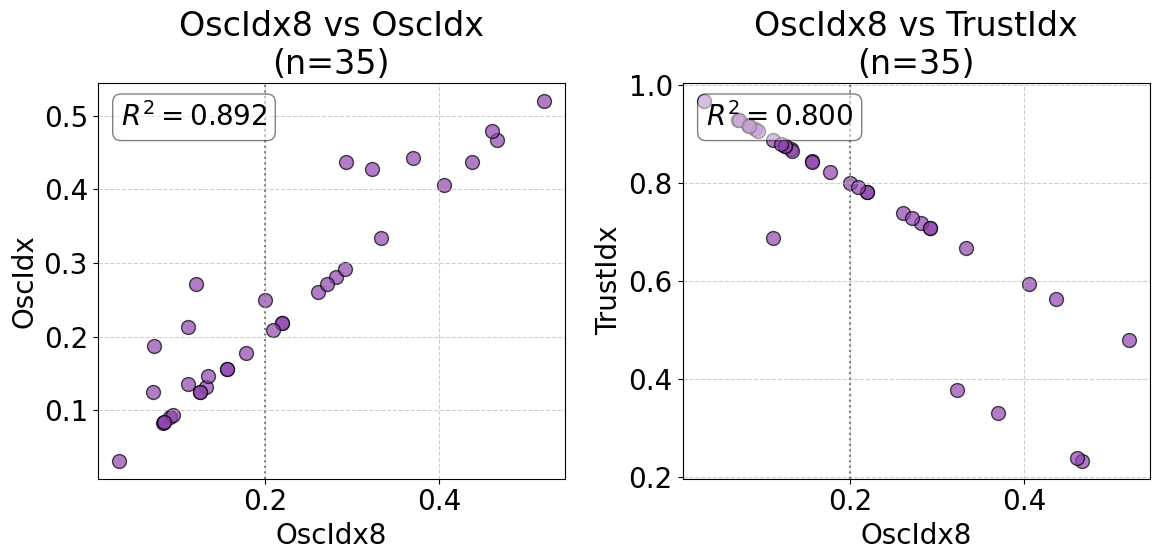

In [14]:
from scipy import stats

def draw_on_scatter(ax, df, x_var, y_var, plot_title, x_axis_name, y_axis_name):
    # 1. Create the figure and axis objects
    # figsize sets the width and height in inches
    
    clean_df = df[[x_var, y_var]].dropna()
    x = clean_df[x_var]
    y = clean_df[y_var]


    r_pearson, _ = stats.pearsonr(x, y)
    r_squared = r_pearson**2

    #fig, ax = plt.subplots(figsize=(10, 6))

    # 2. Plot the scatter points
    # x: horizontal axis (e.g., Accuracy)
    # y: vertical axis (e.g., Error)
    ax.scatter(
        x, 
        y, 
        alpha=0.7,           # Transparency (useful if points overlap)
        edgecolors='black',  # Outline color for better definition
        s=100,                 # Size of the points
        c='#8E44AD',
    )

    # 3. Add descriptive labels and title
    text_str = f'$R^2 = {r_squared:.3f}$'
    ax.text(0.05, 0.95, text_str, transform=ax.transAxes, #fontsize=12,
            verticalalignment='top', horizontalalignment='left',\
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    
    ax.set_title(plot_title + (f"\n(n={len(x)})"), #fontsize=14, 
                 #fontweight='bold'
                 )
    ax.set_xlabel(x_axis_name, #fontsize=12
                  )
    ax.set_ylabel(y_axis_name, #fontsize=12
                  )

    # 4. Add a grid for better readability
    ax.grid(True, linestyle='--', alpha=0.6)

    # 5. Optional: Add a 45-degree reference line or a threshold line
    # Example: a horizontal line representing a "maximum acceptable error"
    ax.axvline(x=0.2, color='grey', linestyle=':', label='Error Threshold')

    # 6. Add legend if you have reference lines
    #ax.legend(loc="best")

    # 7. Final layout adjustment
    #plt.tight_layout()

    # 8. Show the plot
    #plt.show()



import matplotlib
font = {'family': 'sans-serif', 'weight': 'normal', 'size': 20}
matplotlib.rc('font', **font)


fig, axes = plt.subplots(1, 2, figsize=(12, 6))

ax_list = axes.flatten()

draw_on_scatter(ax_list[0], merged_df, "Osc_index-9", "Osc_index", 
                "OscIdx8 vs OscIdx", "OscIdx8", "OscIdx")

draw_on_scatter(ax_list[1], merged_df, "Osc_index-9", "Trust_index", 
                "OscIdx8 vs TrustIdx", "OscIdx8", "TrustIdx")

#draw_on_scatter(ax_list[2], merged_df, "Osc_index-9", "index_exact", 
#                "OscIdx9 vs IndexExact9", "OscIdx9", "IndexExact9")

#draw_on_scatter(ax_list[3], merged_df, "Osc_index-9", "mean_error", 
#                "OscIdx9 vs MeanError9", "OscIdx9", "MeanError9")

plt.tight_layout()
plt.show()

fig.savefig(
    os.path.join(path_save, "indexes.png"), 
    dpi=300,            
    bbox_inches='tight' 
)


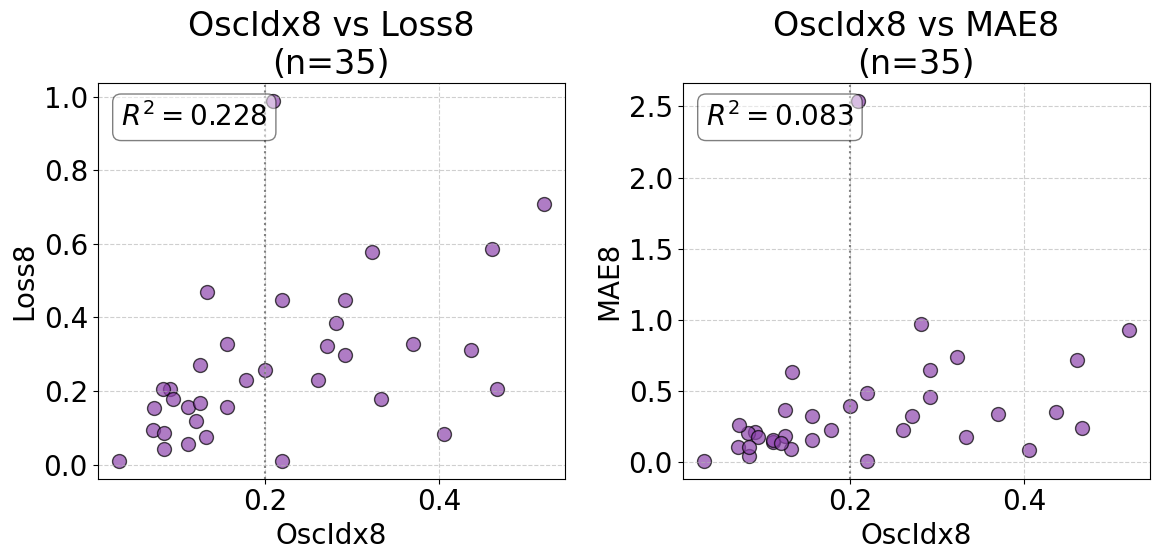

In [15]:
import matplotlib
font = {'family': 'sans-serif', 'weight': 'normal', 'size': 20}
matplotlib.rc('font', **font)



fig, axes = plt.subplots(1, 2, figsize=(12, 6))

ax_list = axes.flatten()

merged_df["Loss8"] = 1 - merged_df["index_exact"]
draw_on_scatter(ax_list[0], merged_df, "Osc_index-9", "Loss8", 
               "OscIdx8 vs Loss8", "OscIdx8", "Loss8")

draw_on_scatter(ax_list[1], merged_df, "Osc_index-9", "mean_error", 
                "OscIdx8 vs MAE8", "OscIdx8", "MAE8")
plt.tight_layout()
plt.show()

fig.savefig(
    os.path.join(path_save, "indexes_other.png"), 
    dpi=300,            
    bbox_inches='tight' 
)



In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def get_significance_stars(pval):
    if pval < 0.0001:
        return "****"
    elif pval < 0.001:
        return "***"
    elif pval < 0.01:
        return "**"
    elif pval < 0.05:
        return "*"
    else:
        return "ns"

def plot_metric_by_quality_group(merged_df, quality_col, quality_name, target_col, target_name,
                                    threshold, higher_is_worse=True, path_save=None):
    """
    quality_col: e.g. 'Indic_std-9' (OscIdx8) or 'Trust_index' (TrustIdx)
    quality_name: display name for the x-axis label, e.g. 'OscIdx8' or 'TrustIdx'
    target_col: e.g. MAE8 or Loss8 column (manual ground truth)
    higher_is_worse: True for OscIdx8 (high value = unreliable microwell),
                      False for TrustIdx (high value = reliable microwell)
    """
    scale = 4
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.size': 6 * scale,
        'axes.labelsize': 7 * scale,
        'axes.titlesize': 7 * scale,      # for axes
        'figure.titlesize': 7 * scale,    # whole figure
        'xtick.labelsize': 4 * scale,
        'ytick.labelsize': 4 * scale,
        'legend.fontsize': 4 * scale,
    })

    df = merged_df.copy()

    # define the two groups based on threshold and metric direction
    if higher_is_worse:
        group_bad = f"{quality_name} >= {threshold}"
        group_good = f"{quality_name} < {threshold}"
        df["quality_group"] = np.where(df[quality_col] < threshold, group_good, group_bad)
    else:
        group_bad = f"{quality_name} <= {threshold}"
        group_good = f"{quality_name} > {threshold}"
        df["quality_group"] = np.where(df[quality_col] > threshold, group_good, group_bad)

    fig, ax = plt.subplots(figsize=(1.5 * scale, 1.5 * scale))
    sns.boxplot(data=df, x="quality_group", y=target_col, ax=ax,
                    order=[group_good, group_bad],
                    palette=["#7A34AC", "#B19CD9"])
    ax.set_xlabel("")
    ax.set_ylabel(target_name)

    # statistical test between the two groups
    g_good = df[df["quality_group"] == group_good][target_col].dropna()
    g_bad = df[df["quality_group"] == group_bad][target_col].dropna()
    stat, pval = stats.mannwhitneyu(g_good, g_bad, alternative="two-sided")
    stars = get_significance_stars(pval)

    # draw significance bracket above the two boxes
    y_max = df[target_col].max()
    y_bracket = y_max * 1.05
    y_text = y_max * 1.08
    ax.plot([0, 0, 1, 1], [y_bracket, y_bracket * 1.02, y_bracket * 1.02, y_bracket],
            lw=1.5, color="black")
    ax.text(0.5, y_text, stars, ha="center", va="bottom")
    ax.set_ylim(top=y_max * 1.2)

    ax.set_title(target_name)

    plt.tight_layout()
    if path_save:
        fig.savefig(f"{path_save}/{quality_col}_{target_name}_boxplot.svg",
                    bbox_inches="tight")
        fig.savefig(f"{path_save}/{quality_col}_{target_name}_boxplot.png", dpi=300,
                            bbox_inches="tight")
    plt.show()

C:\Users\tizia\AppData\Local\Temp\ipykernel_31500\1219525556.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="quality_group", y=target_col, ax=ax,


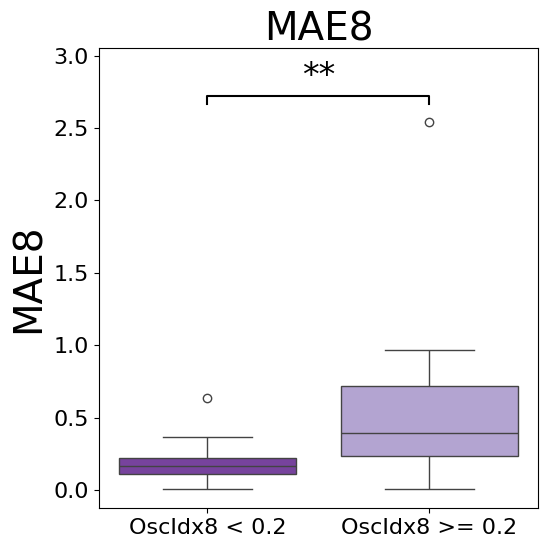

In [17]:
# OscIdx8 vs MAE8
plot_metric_by_quality_group(
    merged_df, quality_col="Osc_index-9", quality_name="OscIdx8",
    target_col="mean_error", target_name="MAE8",
    threshold=0.2, higher_is_worse=True, path_save="Figures"
)


C:\Users\tizia\AppData\Local\Temp\ipykernel_31500\1219525556.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="quality_group", y=target_col, ax=ax,


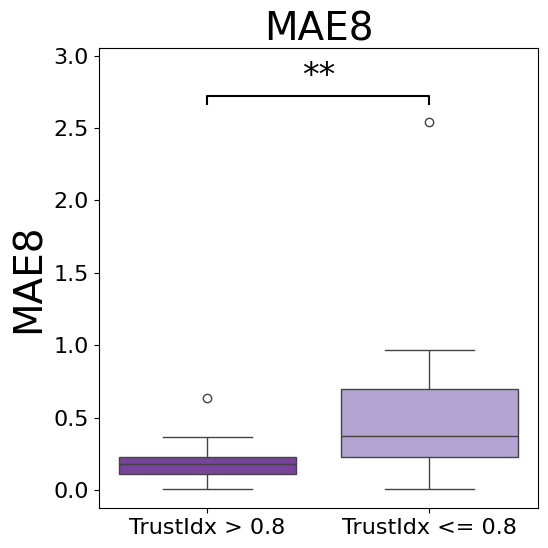

In [18]:
# TrustIdx vs MAE8
plot_metric_by_quality_group(
    merged_df, quality_col="Trust_index", quality_name="TrustIdx",
    target_col="mean_error", target_name="MAE8",
    threshold=0.8, higher_is_worse=False, path_save="Figures"
)

In [19]:
print(merged_df["mean_error"].describe())
mae_threshold = merged_df['mean_error'].quantile(0.75)
print(mae_threshold)

count    35.000000
mean      0.376500
std       0.450754
min       0.010417
25%       0.149206
50%       0.229167
75%       0.425040
max       2.541667
Name: mean_error, dtype: float64
0.42503987240829344


In [20]:
print(merged_df)

                    ResultID   CellType  ColonySize    T1  T2.1  T2.2  T3.1  \
6858   (HPC_3000)_tile008_e2  cordblood         4.0   5.0  40.0   NaN  52.5   
6903   (HPC_3000)_tile019_c2  cordblood         7.0  22.5  37.5  37.5  50.0   
6921   (HPC_3000)_tile021_d3  cordblood         8.0  35.0  42.5  42.5  45.0   
6983   (HPC_3000)_tile033_d1  cordblood         3.0  40.0  50.0   NaN   NaN   
7114   (HPC_3000)_tile053_b4  cordblood        31.0  17.5  27.5  27.5  37.5   
7138   (HPC_3000)_tile056_d1  cordblood        19.0  27.5  27.5  30.0  40.0   
7369   (HPC_3000)_tile094_d4  cordblood         8.0  32.5  45.0  45.0  55.0   
9919      TR1-A01_tile003_b2        oci        23.0   5.0  25.0  30.0  45.0   
10167     TR1-A01_tile051_a1        oci         7.0   5.0  30.0  50.0  50.0   
10245     TR1-A01_tile068_b4        oci        22.0  10.0  20.0  20.0  40.0   
10248     TR1-A01_tile069_b2        oci        12.0  25.0  45.0  45.0  65.0   
10453     TR1-A01_tile112_a4        oci        13.0 

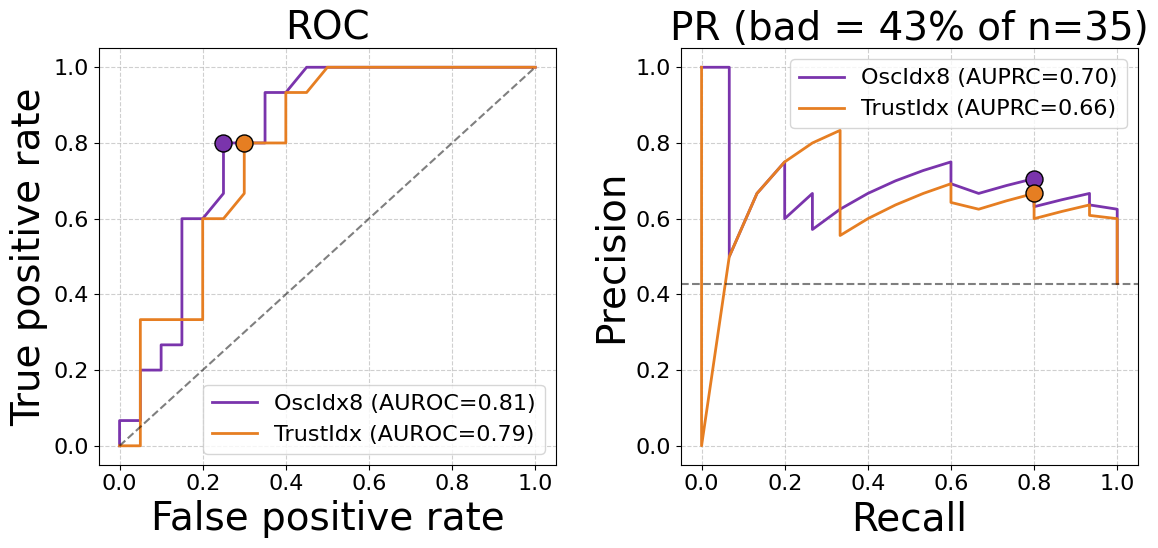

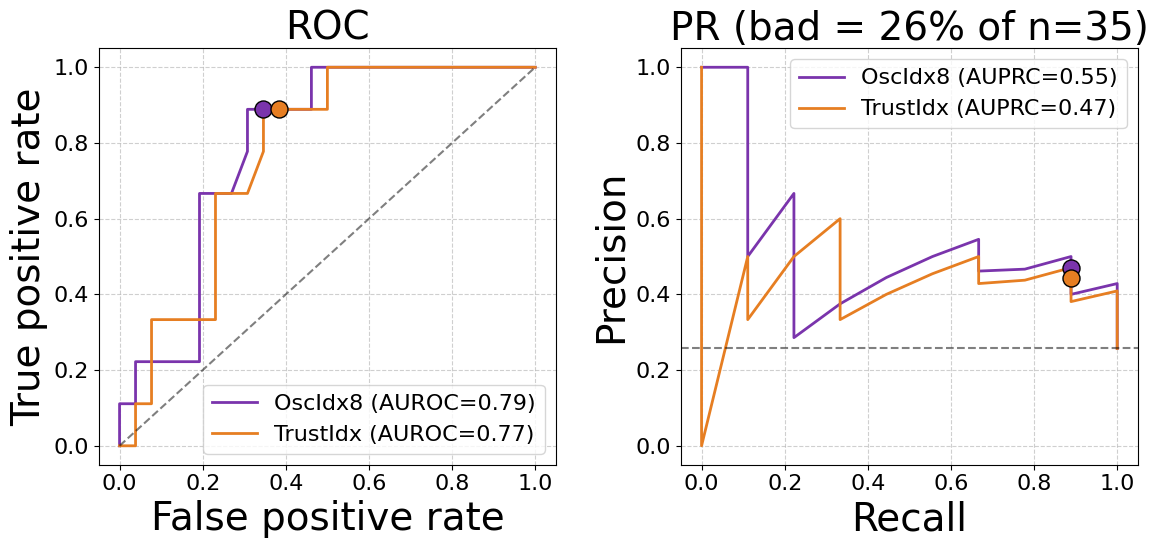

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)

def plot_roc_pr(merged_df, indices, target_col, error_tol, path_save=None):
    """
    indices: list of dicts, one per index, e.g.
      [dict(col="Osc_index-9", name="OscIdx8", threshold=0.2, higher_is_worse=True),
       dict(col="Trust_index", name="TrustIdx", threshold=0.8, higher_is_worse=False)]
    target_col: manual ground-truth error column (e.g. MAE8)
    error_tol: error above this value = "bad" microwell/frame
    """
    cols = [i["col"] for i in indices]
    df = merged_df[cols + [target_col]].dropna()
    y = (df[target_col] > error_tol).astype(int).values
    prevalence = y.mean()

    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 6))
    colors = ["#7A34AC", "#E67E22", "#2E86C1"]

    for k, idx in enumerate(indices):
        # orient so that HIGHER score = more likely bad
        s = df[idx["col"]].values if idx["higher_is_worse"] else -df[idx["col"]].values
        auroc = roc_auc_score(y, s)
        auprc = average_precision_score(y, s)
        fpr, tpr, _ = roc_curve(y, s)
        prec, rec, _ = precision_recall_curve(y, s)
        c = colors[k]

        ax_roc.plot(fpr, tpr, color=c, lw=2, label=f"{idx['name']} (AUROC={auroc:.2f})")
        ax_pr.plot(rec, prec, color=c, lw=2, label=f"{idx['name']} (AUPRC={auprc:.2f})")

        # operating point of your fixed threshold
        if idx["higher_is_worse"]:
            flagged = df[idx["col"]].values >= idx["threshold"]
        else:
            flagged = df[idx["col"]].values <= idx["threshold"]
        tp = (flagged & (y == 1)).sum()
        tpr_op = tp / max((y == 1).sum(), 1)
        fpr_op = (flagged & (y == 0)).sum() / max((y == 0).sum(), 1)
        prec_op = tp / max(flagged.sum(), 1)
        ax_roc.scatter(fpr_op, tpr_op, s=150, color=c, edgecolors="black", zorder=5)
        ax_pr.scatter(tpr_op, prec_op, s=150, color=c, edgecolors="black", zorder=5)

    ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax_pr.axhline(prevalence, color="k", ls="--", alpha=0.5)   # random baseline

    ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
    ax_pr.set(xlabel="Recall", ylabel="Precision",
              title=f"PR (bad = {prevalence:.0%} of n={len(y)})")
    for ax in (ax_roc, ax_pr):
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend(loc="best")

    plt.tight_layout()
    if path_save:
        fig.savefig(f"{path_save}/roc_pr_{error_tol}.png", dpi=300, bbox_inches="tight")
        fig.savefig(f"{path_save}/roc_pr_{error_tol}.svg", bbox_inches="tight")
    plt.show()

plot_roc_pr(
    merged_df,
    indices=[dict(col="Osc_index-9", name="OscIdx8", threshold=0.2, higher_is_worse=True),
             dict(col="Trust_index", name="TrustIdx", threshold=0.8, higher_is_worse=False)],
    target_col="mean_error",      # your manual ground-truth error column
    error_tol=0.3,            # choose this on scientific grounds, see below
    path_save=path_save,
)

plot_roc_pr(
    merged_df,
    indices=[dict(col="Osc_index-9", name="OscIdx8", threshold=0.2, higher_is_worse=True),
             dict(col="Trust_index", name="TrustIdx", threshold=0.8, higher_is_worse=False)],
    target_col="mean_error",      # your manual ground-truth error column
    error_tol=0.4,            # choose this on scientific grounds, see below
    path_save=path_save,
)

In [22]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

def bootstrap_ci(merged_df, indices, target_col, error_tol,
                 group_col=None, n_boot=2000, seed=0):
    """
    group_col: column with the microwell ID. If None, each row is treated
               as one independent well (use this if merged_df is one row per well).
    Returns a DataFrame with point estimate and 95% CI for each metric.
    """
    cols = [i["col"] for i in indices]
    keep = cols + [target_col] + ([group_col] if group_col else [])
    df = merged_df[keep].dropna().reset_index(drop=True)
    y = (df[target_col] > error_tol).astype(int).values

    # row indices belonging to each well
    if group_col:
        well_rows = [g.index.values for _, g in df.groupby(group_col)]
    else:
        well_rows = [np.array([i]) for i in range(len(df))]

    def metrics(rows):
        yy = y[rows]
        if yy.sum() == 0 or yy.sum() == len(yy):
            return None                       # need both classes
        out = {}
        for idx in indices:
            v = df[idx["col"]].values[rows]
            score = v if idx["higher_is_worse"] else -v
            flagged = v >= idx["threshold"] if idx["higher_is_worse"] else v <= idx["threshold"]
            tp = (flagged & (yy == 1)).sum()
            n_name = idx["name"]
            out[f"{n_name} AUROC"] = roc_auc_score(yy, score)
            out[f"{n_name} AUPRC"] = average_precision_score(yy, score)
            out[f"{n_name} recall@thr"] = tp / (yy == 1).sum()
            out[f"{n_name} FPR@thr"] = (flagged & (yy == 0)).sum() / (yy == 0).sum()
            out[f"{n_name} precision@thr"] = tp / flagged.sum() if flagged.sum() > 0 else np.nan
        if len(indices) == 2:
            a, b = indices[0]["name"], indices[1]["name"]
            out[f"AUROC diff ({a} - {b})"] = out[f"{a} AUROC"] - out[f"{b} AUROC"]
        out["prevalence"] = yy.mean()
        return out

    point = metrics(np.arange(len(df)))

    rng = np.random.default_rng(seed)
    boots, skipped = [], 0
    for _ in range(n_boot):
        pick = rng.integers(0, len(well_rows), len(well_rows))
        rows = np.concatenate([well_rows[p] for p in pick])
        m = metrics(rows)
        if m is None:
            skipped += 1
            continue
        boots.append(m)

    boots = pd.DataFrame(boots)
    summary = pd.DataFrame({
        "estimate": pd.Series(point),
        "CI 2.5%": boots.quantile(0.025),
        "CI 97.5%": boots.quantile(0.975),
    }).round(3)
    print(f"n wells = {len(well_rows)}, bad = {y.sum()} ({y.mean():.0%}), "
          f"valid resamples = {len(boots)}/{n_boot}")
    return summary

indices = [dict(col="Osc_index-9", name="OscIdx8", threshold=0.2, higher_is_worse=True),
           dict(col="Trust_index", name="TrustIdx", threshold=0.8, higher_is_worse=False)]

for tol in (0.3, 0.4):
    print(f"\n=== MAE > {tol} ===")
    print(bootstrap_ci(merged_df, indices, "mean_error", error_tol=tol))


=== MAE > 0.3 ===
n wells = 35, bad = 15 (43%), valid resamples = 2000/2000
                                 estimate  CI 2.5%  CI 97.5%
OscIdx8 AUROC                       0.813    0.660     0.947
OscIdx8 AUPRC                       0.704    0.477     0.937
OscIdx8 recall@thr                  0.800    0.571     1.000
OscIdx8 FPR@thr                     0.250    0.062     0.450
OscIdx8 precision@thr               0.706    0.471     0.923
TrustIdx AUROC                      0.787    0.620     0.922
TrustIdx AUPRC                      0.663    0.452     0.912
TrustIdx recall@thr                 0.800    0.571     1.000
TrustIdx FPR@thr                    0.300    0.111     0.524
TrustIdx precision@thr              0.667    0.438     0.875
AUROC diff (OscIdx8 - TrustIdx)     0.027   -0.028     0.112
prevalence                          0.429    0.257     0.600

=== MAE > 0.4 ===
n wells = 35, bad = 9 (26%), valid resamples = 1999/2000
                                 estimate  CI 2.5%  CI

In [23]:
import numpy as np
from sklearn.model_selection import RepeatedStratifiedKFold

def youden_thr(v, y, hiw):
    best, bj = None, -1
    for t in np.unique(v):
        f = v >= t if hiw else v <= t
        j = (f & (y==1)).sum()/max((y==1).sum(),1) - (f & (y==0)).sum()/max((y==0).sum(),1)
        if j > bj: best, bj = t, j
    return best


def nested_cv(df, col, hiw, target="mean_error", tol=0.3, n_splits=5, n_repeats=200):
    df = df.dropna(subset=[col, target]).reset_index(drop=True)
    v, y = df[col].values, (df[target] > tol).astype(int).values
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=0)
    thrs, rec, fpr = [], [], []
    flags = np.zeros(len(df), bool); r = 0
    for k, (tr, te) in enumerate(cv.split(v, y)):
        t = youden_thr(v[tr], y[tr], hiw); thrs.append(t)
        flags[te] = (v[te] >= t) if hiw else (v[te] <= t)
        if (k + 1) % n_splits == 0:            # one full repeat done
            rec.append((flags & (y==1)).sum() / (y==1).sum())
            fpr.append((flags & (y==0)).sum() / (y==0).sum())
    q = lambda a: np.round(np.percentile(a, [2.5, 50, 97.5]), 3)
    print(f"{col}: selected thr {q(thrs)} | out-of-fold recall {q(rec)} | FPR {q(fpr)}")

for tol in (0.3, 0.4):
    print(f"--- MAE > {tol} (all validation wells) ---")
    nested_cv(merged_df, "Osc_index-9", True, tol=tol)
    nested_cv(merged_df, "Trust_index", False, tol=tol)

--- MAE > 0.3 (all validation wells) ---
Osc_index-9: selected thr [0.125 0.133 0.208] | out-of-fold recall [0.667 0.8   0.868] | FPR [0.35 0.4  0.45]
Trust_index: selected thr [0.79  0.867 0.875] | out-of-fold recall [0.665 0.8   0.867] | FPR [0.4  0.45 0.5 ]
--- MAE > 0.4 (all validation wells) ---
Osc_index-9: selected thr [0.133 0.208 0.281] | out-of-fold recall [0.667 0.778 0.889] | FPR [0.308 0.423 0.462]
Trust_index: selected thr [0.719 0.792 0.867] | out-of-fold recall [0.556 0.778 0.889] | FPR [0.346 0.423 0.5  ]
